In [3]:
#to predict a players next-game points, is it better to use his season average or recent form?
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

df = pd.read_csv("nba_dailyleaders_full.csv").drop(columns=["Unnamed: 0", "Unnamed: 1", "Unnamed: 2"])
print(df.shape)
df.head()

(28716, 26)


,Player,Tm,Opp,Result,MP,FG,FGA,FG%,3P,3PA,...,TRB,AST,STL,BLK,TOV,PF,PTS,+/-,GmSc,Date
0,Luka Dončić,LAL,GSW,L,40:59,17.0,27.0,0.630,2.0,10.0,...,12.0,9.0,2.0,1.0,3.0,1.0,43.0,-8.0,38.9,2025-10-21
1,Alperen Şengün,HOU,OKC,L,48:53,12.0,24.0,0.500,5.0,8.0,...,11.0,7.0,2.0,1.0,4.0,5.0,39.0,9.0,33.1,2025-10-21
2,Jimmy Butler,GSW,LAL,W,34:44,7.0,14.0,0.500,1.0,2.0,...,5.0,4.0,1.0,0.0,1.0,4.0,31.0,20.0,27.5,2025-10-21
3,Shai Gilgeous-Alexander,OKC,HOU,W,47:13,12.0,26.0,0.462,1.0,9.0,...,5.0,5.0,2.0,2.0,3.0,2.0,35.0,3.0,24.6,2025-10-21
4,Austin Reaves,LAL,GSW,L,36:20,9.0,16.0,0.563,1.0,5.0,...,5.0,9.0,2.0,0.0,5.0,5.0,26.0,-14.0,20.4,2025-10-21


In [4]:
#cleaning
df["Date"] = pd.to_datetime(df["Date"])

mp = df["MP"].str.split(":", expand = True).astype(float)
df["minutes"] = mp[0] + mp[1] / 60

team_dates = df[["Tm", "Date"]].drop_duplicates().sort_values(["Tm", "Date"])
team_dates["gnum"] = team_dates.groupby("Tm").cumcount() +1
reg = team_dates[team_dates["gnum"] <= 82][["Tm", "Date"]]
df = df.merge(reg, on=["Tm", "Date"])

df = df[df["minutes"] > 0].sort_values(["Player", "Date"]).reset_index(drop=True)
print(df.shape, df["Date"].max())

(26643, 27) 2026-04-12 00:00:00


In [5]:
g = df.groupby("Player")

df["games_before"] = g.cumcount()
df["season_avg"]   = g["PTS"].transform(lambda s: s.expanding().mean().shift(1))
df["last5"]        = g["PTS"].transform(lambda s: s.rolling(5).mean().shift(1))
df["last10"]       = g["PTS"].transform(lambda s: s.rolling(10).mean().shift(1))
df["last5_min"]     = g["minutes"].transform(lambda s: s.rolling(5).mean().shift(1))
df["season_min"]   = g["minutes"].transform(lambda s: s.expanding().mean().shift(1))

In [6]:
name = df["Player"].value_counts().index[0]
ex = df[df["Player"] == name].reset_index(drop = True)
print(ex.loc[10, "last5"], ex.loc[5:9, "PTS"].mean())
print(ex.loc[10,"season_avg"], ex.loc[0:9,"PTS"].mean())

9.2 9.2
8.7 8.7


In [7]:
d = df[(df["games_before"] >= 10 ) & (df["season_min"] >= 15)]
d = d.dropna(subset=["season_avg","last5","last10","last5_min"]).copy()
print(d.shape, d["Player"].nunique())

(16862, 33) 393


In [8]:
cut = pd.Timestamp("2026-02-15")
train = d[d["Date"] < cut]
test = d[d["Date"] >= cut]
print(len(train), len(test))

10338 6524


In [9]:
mae = {
    "Season avg": mean_absolute_error(test["PTS"], test["season_avg"]),
    "Last 5":     mean_absolute_error(test["PTS"], test["last5"]),
    "Last 10":    mean_absolute_error(test["PTS"], test["last10"]),
}

feats = ["season_avg", "last5", "last5_min"]
model = LinearRegression().fit(train[feats], train["PTS"])
mae["Blend (regression)"] = mean_absolute_error(test["PTS"], model.predict(test[feats]))
mae["Guess the average"] = mean_absolute_error(test["PTS"], np.full(len(test), train["PTS"].mean()))

for k, v in mae.items():
    print(f"{k:20s} {v:.2f}")
print(dict(zip(feats, model.coef_.round(3).tolist())))

Season avg           5.18
Last 5               5.27
Last 10              5.11
Blend (regression)   5.05
Guess the average    6.78
{'season_avg': 0.709, 'last5': 0.148, 'last5_min': 0.106}


In [10]:
test = test.assign(
  gap = test["last5"] - test["season_avg"],
  next_vs_avg = test["PTS"] - test["season_avg"]
)

test["bucket"] = pd.qcut(test["gap"], 5, labels=["Coldest", "Cold", "Neutral", "Hot", "Hottest"])

summary = test.groupby("bucket", observed=True).agg(
    gap=("gap", "mean"),
    next_vs_avg=("next_vs_avg","mean"),
    n=("gap","size"),
).round(2)
print(summary)

          gap  next_vs_avg     n
bucket                          
Coldest -4.13        -1.35  1305
Cold    -1.56        -0.64  1305
Neutral  0.16        -0.07  1304
Hot      1.98         1.17  1305
Hottest  5.39         2.87  1305


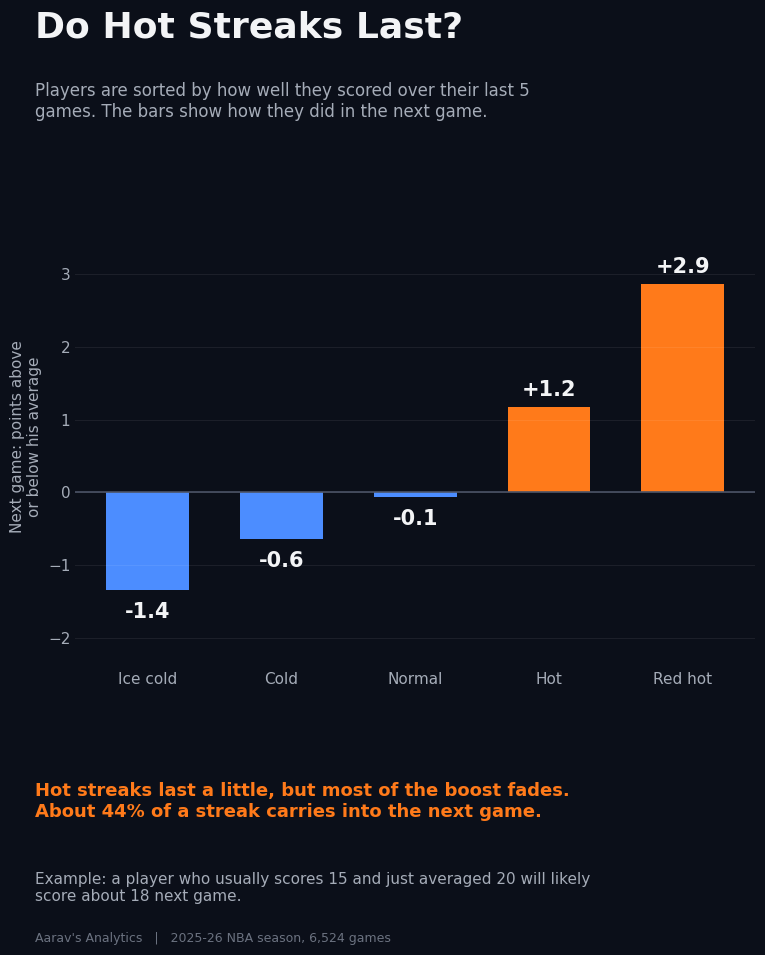

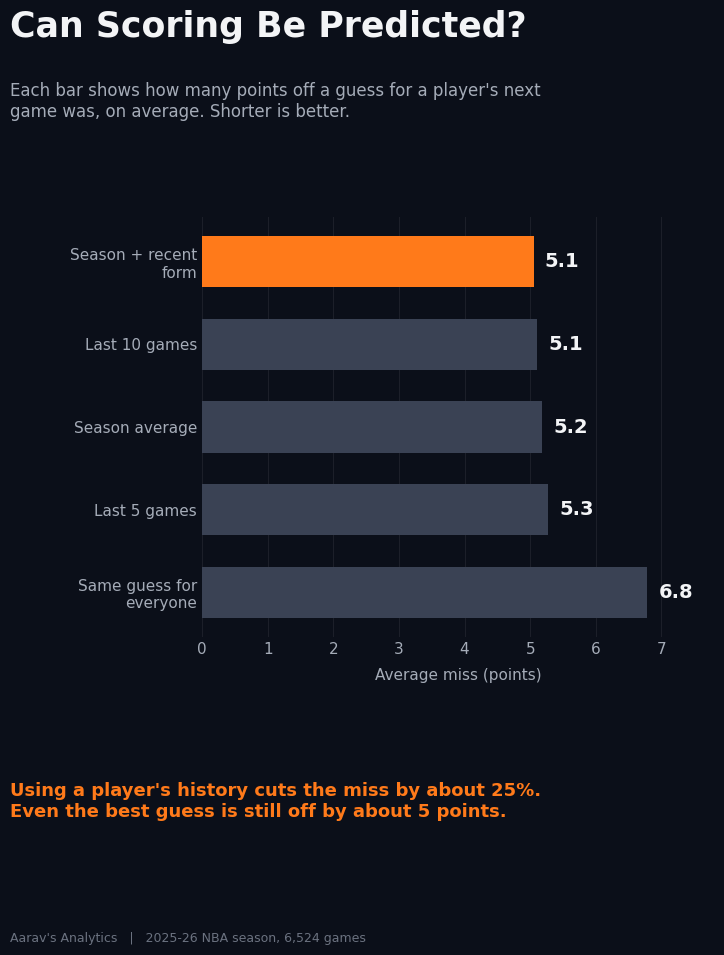

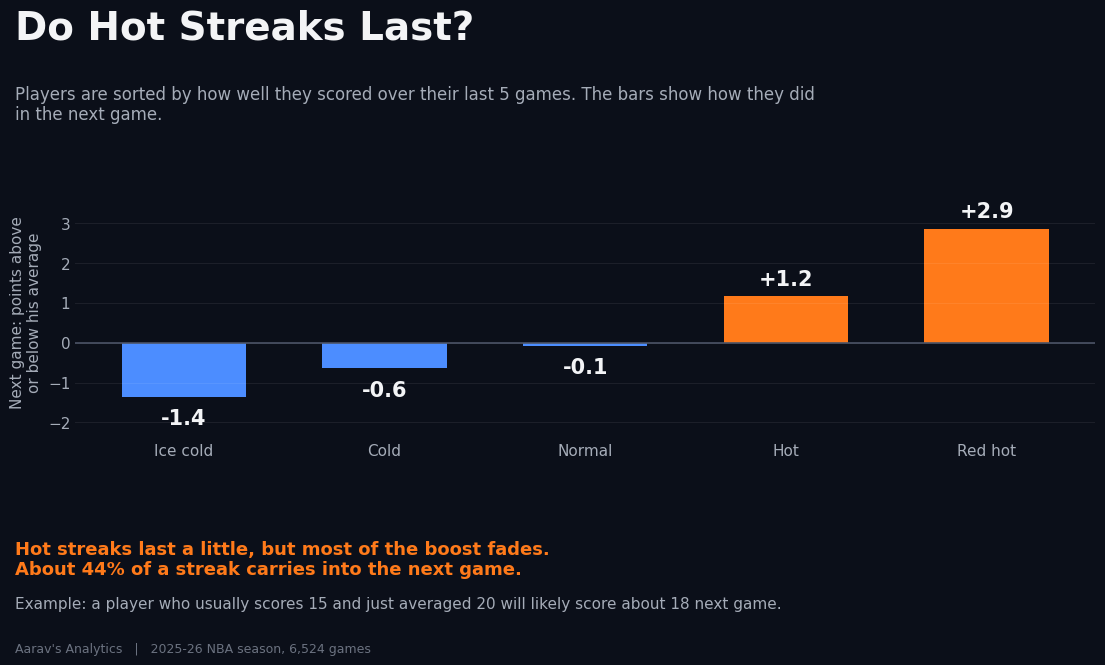

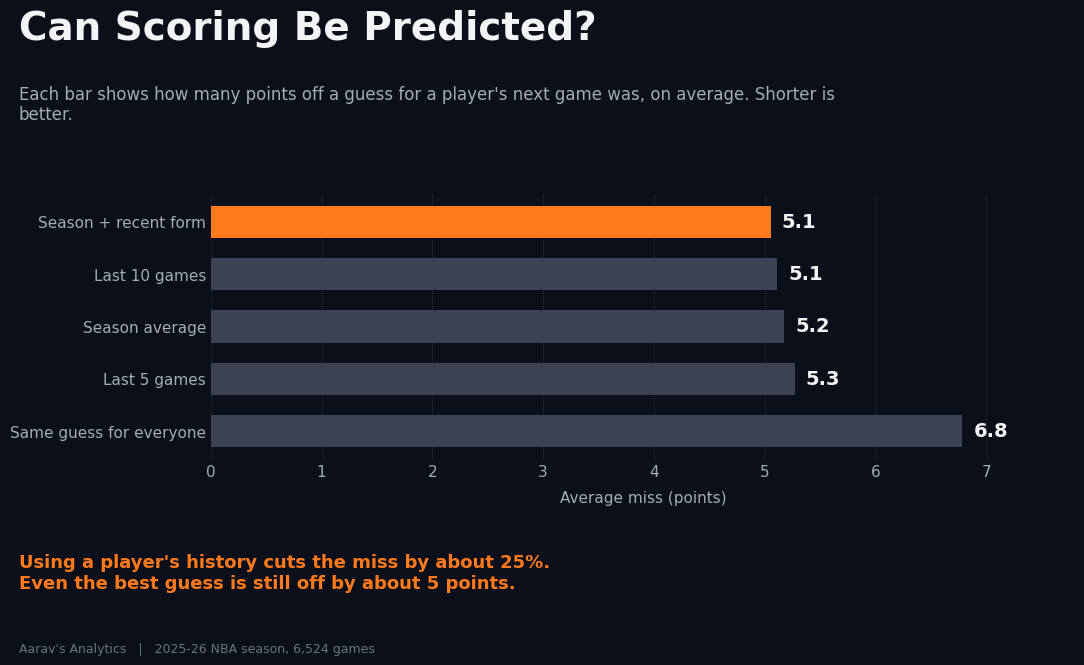

In [11]:
import textwrap

BG, ACCENT, TEXT, MUTED, COLD, GRAY = "#0B0F19", "#FF7A1A", "#F3F4F6", "#A5ACB8", "#4C8DFF", "#3A4254"

mae_plain = {
    "Same guess for everyone": mae["Guess the average"],
    "Last 5 games":            mae["Last 5"],
    "Season average":          mae["Season avg"],
    "Last 10 games":           mae["Last 10"],
    "Season + recent form":    mae["Blend (regression)"],
}

def footer(fig):
    fig.text(0.06, 0.025, f"Aarav's Analytics   |   2025-26 NBA season, {len(test):,} games",
             color="#6B7280", fontsize=9)

def chart1(figsize, fname):
    fig = plt.figure(figsize=figsize, facecolor=BG)
    tall = figsize[1] > figsize[0]
    ax = fig.add_axes([0.11, 0.30 if tall else 0.33, 0.85, 0.46 if tall else 0.36])
    ax.set_facecolor(BG)

    labels = ["Ice cold", "Cold", "Normal", "Hot", "Red hot"]
    vals = summary["next_vs_avg"].tolist()
    bars = ax.bar(labels, vals, color=[COLD if v < 0 else ACCENT for v in vals], width=0.62)
    for b, v in zip(bars, vals):
        ax.annotate(f"{v:+.1f}", (b.get_x() + b.get_width() / 2, v),
                    xytext=(0, 8 if v >= 0 else -20), textcoords="offset points",
                    ha="center", color=TEXT, fontsize=15, fontweight="bold")
    ax.axhline(0, color="#4B5366", lw=1.2)
    ax.margins(y=0.25)
    ax.set_ylabel("Next game: points above\nor below his average", color=MUTED, fontsize=11)
    ax.tick_params(colors=MUTED, labelsize=11, length=0)
    ax.grid(axis="y", color="white", alpha=0.07)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)

    carry = ((summary["next_vs_avg"].iloc[-1] - summary["next_vs_avg"].iloc[0]) /
             (summary["gap"].iloc[-1] - summary["gap"].iloc[0]))
    hot = summary.iloc[-1]

    fig.text(0.06, 0.93 if tall else 0.90, "Do Hot Streaks Last?",
             color=TEXT, fontsize=26 if tall else 28, fontweight="bold")
    q = ("Players are sorted by how well they scored over their last 5 games. "
         "The bars show how they did in the next game.")
    fig.text(0.06, 0.885 if tall else 0.835, textwrap.fill(q, 62 if tall else 95),
             color=MUTED, fontsize=12, va="top")
    take = ("Hot streaks last a little, but most of the boost fades.\n"
            f"About {carry:.0%} of a streak carries into the next game.")
    fig.text(0.06, 0.185, take, color=ACCENT, fontsize=13, fontweight="bold", va="top")
    ex = (f"Example: a player who usually scores 15 and just averaged {15 + hot['gap']:.0f} "
          f"will likely score about {15 + hot['next_vs_avg']:.0f} next game.")
    fig.text(0.06, 0.095 if tall else 0.105, textwrap.fill(ex, 72 if tall else 150),
             color=MUTED, fontsize=11, va="top")
    footer(fig)
    fig.savefig(fname, dpi=160, facecolor=BG)
    plt.show()
    plt.close(fig)

def chart2(figsize, fname):
    fig = plt.figure(figsize=figsize, facecolor=BG)
    tall = figsize[1] > figsize[0]
    ax = fig.add_axes([0.30 if tall else 0.22, 0.33 if tall else 0.30,
                       0.64 if tall else 0.72, 0.42 if tall else 0.38])
    ax.set_facecolor(BG)

    items = sorted(mae_plain.items(), key=lambda kv: -kv[1])
    labels = [textwrap.fill(k, 16 if tall else 26) for k, _ in items]
    vals = [v for _, v in items]
    cols = [ACCENT if "recent form" in k else GRAY for k, _ in items]
    bars = ax.barh(labels, vals, color=cols, height=0.62)
    for b, v in zip(bars, vals):
        ax.annotate(f"{v:.1f}", (v, b.get_y() + b.get_height() / 2), xytext=(8, 0),
                    textcoords="offset points", va="center", color=TEXT, fontsize=14, fontweight="bold")
    ax.set_xlim(0, max(vals) * 1.15)
    ax.set_xlabel("Average miss (points)", color=MUTED, fontsize=11, labelpad=8)
    ax.tick_params(colors=MUTED, labelsize=11, length=0)
    ax.xaxis.grid(True, color="white", alpha=0.07)
    ax.set_axisbelow(True)
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)

    best, worst = min(vals), max(vals)
    fig.text(0.06, 0.93 if tall else 0.90, "Can Scoring Be Predicted?",
             color=TEXT, fontsize=25 if tall else 28, fontweight="bold")
    q = ("Each bar shows how many points off a guess for a player's next game was, "
         "on average. Shorter is better.")
    fig.text(0.06, 0.885 if tall else 0.835, textwrap.fill(q, 62 if tall else 95),
             color=MUTED, fontsize=12, va="top")
    take = (f"Using a player's history cuts the miss by about {(worst - best) / worst:.0%}.\n"
            f"Even the best guess is still off by about {best:.0f} points.")
    fig.text(0.06, 0.185 if tall else 0.165, take, color=ACCENT, fontsize=13, fontweight="bold", va="top")
    footer(fig)
    fig.savefig(fname, dpi=160, facecolor=BG)
    plt.show()
    plt.close(fig)

for size, tag in [((8, 10), "instagram"), ((12, 7), "github")]:
    chart1(size, f"hot_streaks_{tag}.png")
    chart2(size, f"accuracy_{tag}.png")